# PlantNet-CNN Basic

Plant disease classification model notebook.


In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
import random

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Rescaling

from tensorflow.keras.models import Sequential
from tensorflow.keras.initializers import GlorotNormal
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization,GlobalAveragePooling2D, MaxPool2D

from keras.models import load_model
from keras.callbacks import ModelCheckpoint, EarlyStopping

from sklearn.metrics import confusion_matrix,classification_report

import json

import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Check if a previously saved model exists and load it
model_path = '/content/drive/MyDrive/plant_disease_model_checkpoint.h5'
if os.path.exists(model_path):
    print("✅ Model loaded from previous checkpoint.")
    model = load_model(model_path)
else:
    print("🆕 No checkpoint found, proceeding with new model.")

🆕 No checkpoint found, proceeding with new model.


In [ ]:

from tensorflow.keras.callbacks import ModelCheckpoint

# Set checkpoint to save the best model based on validation accuracy
checkpoint = ModelCheckpoint(
    '/content/drive/MyDrive/plant_disease_model_checkpoint.h5',
    save_best_only=True,
    monitor='val_accuracy',
    mode='max',
    verbose=1
)


# Data Preprocessing


## Losing data from kaggel

In [ ]:
# Step 1: Upload kaggle.json (from your Kaggle account)
from google.colab import files
files.upload()  # Choose kaggle.json

# Step 2: Move kaggle.json to correct location and set permissions
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Step 3: Install Kaggle CLI
!pip install -q kaggle

# Step 4: Download the dataset (Yash Dogra - Speech Commands)
!kaggle datasets download -d vipoooool/new-plant-diseases-dataset
# Step 5: Unzip the dataset
!mkdir -p vipooool
!unzip -q new-plant-diseases-dataset.zip -d vipooool

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset
License(s): copyright-authors


## Training Image preprocessing


In [ ]:
training_set = tf.keras.utils.image_dataset_from_directory(
    '/content/vipooool/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train',
    image_size= (256, 256),
    shuffle=True)


Found 70295 files belonging to 38 classes.


## validation Image preprocessing

In [ ]:
validation_set = tf.keras.utils.image_dataset_from_directory(
    '/content/vipooool/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid',
    image_size= (256, 256),
    shuffle=True,
)

Found 17572 files belonging to 38 classes.


In [ ]:
# show how data store
images, labels = next(iter(training_set))
print(f'shape of image is : {images[0].shape}')
print(f'label  \n{labels[0]}')

shape of image is : (256, 256, 3)
label  
6


In [ ]:
rescale = Rescaling(scale=1.0/255)


In [ ]:
training_set = training_set.map(lambda image,label:(rescale(image),label))
validation_set  = validation_set.map(lambda image,label:(rescale(image),label))

In [ ]:
# show all diseases in dataset
train_dir = '/content/vipooool/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train'

diseases = os.listdir(train_dir)
print(diseases)

['Tomato___Early_blight', 'Raspberry___healthy', 'Peach___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Grape___Esca_(Black_Measles)', 'Strawberry___Leaf_scorch', 'Corn_(maize)___Northern_Leaf_Blight', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Squash___Powdery_mildew', 'Potato___Early_blight', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Grape___healthy', 'Apple___Black_rot', 'Peach___Bacterial_spot', 'Apple___healthy', 'Tomato___Bacterial_spot', 'Soybean___healthy', 'Grape___Black_rot', 'Apple___Cedar_apple_rust', 'Tomato___Septoria_leaf_spot', 'Corn_(maize)___Common_rust_', 'Pepper,_bell___Bacterial_spot', 'Tomato___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Potato___Late_blight', 'Tomato___Late_blight', 'Strawberry___healthy', 'Tomato___Leaf_Mold', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Blueberry___healthy', 'Corn_(maize)___healthy', 'Tomato___Tomato_mosaic_virus', 'Potato___healthy', 'Apple___Apple_scab', 'Cherry_(including_sour)___hea

In [ ]:
# identify uniqe plant in dataset
plants = []
NumberOfDiseases = 0
for plant in diseases:
    if plant.split('___')[0] not in plants:
        plants.append(plant.split('___')[0])
print(f'number of different plants is :{len(plants)}')
print(plants)

number of different plants is :14
['Tomato', 'Raspberry', 'Peach', 'Cherry_(including_sour)', 'Grape', 'Strawberry', 'Corn_(maize)', 'Squash', 'Potato', 'Apple', 'Soybean', 'Pepper,_bell', 'Orange', 'Blueberry']


In [ ]:
# identify uniqe plant in dataset
train_dir = '/content/vipooool/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train'

diseases = [name for name in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, name))]

nums = {}
for disease in diseases:
    nums[disease] = len(os.listdir(os.path.join(train_dir, disease)))
img_per_class = pd.DataFrame(nums.values(), index=nums.keys(), columns=["Number of images"])
img_per_class

,Number of images
Tomato___Early_blight,1920
Raspberry___healthy,1781
Peach___healthy,1728
Cherry_(including_sour)___Powdery_mildew,1683
Grape___Esca_(Black_Measles),1920
Strawberry___Leaf_scorch,1774
Corn_(maize)___Northern_Leaf_Blight,1908
Grape___Leaf_blight_(Isariopsis_Leaf_Spot),1722
Squash___Powdery_mildew,1736
Potato___Early_blight,1939


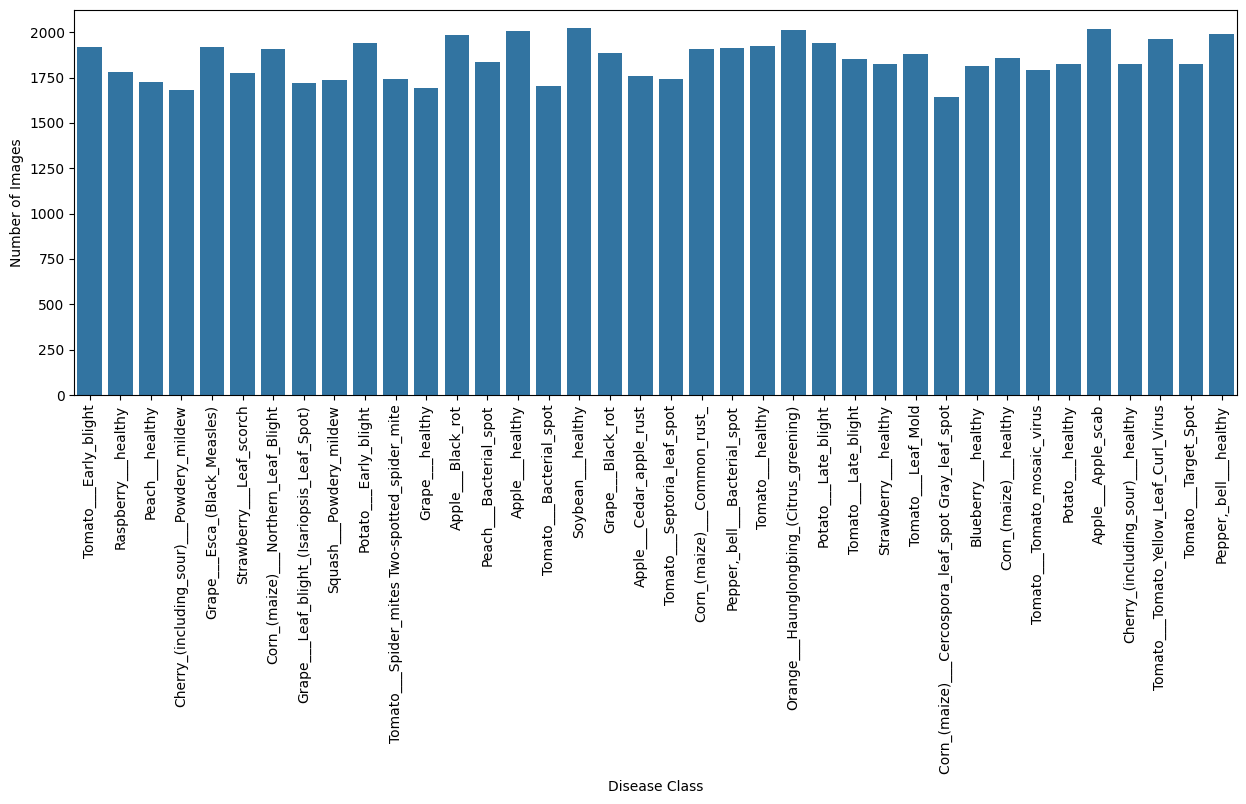

In [ ]:
train_dir = '/content/vipooool/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train'

diseases = [name for name in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, name))]

dic = {}
for Class in diseases:
    dic[Class] = len(os.listdir(os.path.join(train_dir, Class)))

df = pd.DataFrame(list(dic.items()), columns=["Disease Class", "Number of Images"])

plt.figure(figsize=(15,5))
sns.barplot(data=df, x='Disease Class', y='Number of Images')
plt.xticks(rotation=90)
plt.show()

In [ ]:
classes = training_set.class_names
base_dir = '/content/vipooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train'

# Counting the number of images in each folder
counts = []
for class_name in classes:
    folder_path = os.path.join(base_dir, class_name)
    counts.append(len([file for file in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, file))]))

# Calculating the total number of images
total_count = sum(counts)

# Calculating the percentages
percentages = [(count / total_count) * 100 for count in counts]

# Sort classes, counts, and percentages in descending order
sorted_indices = sorted(range(len(counts)), key=lambda k: counts[k], reverse=True)
classes = [classes[i] for i in sorted_indices]
counts = [counts[i] for i in sorted_indices]
percentages = [percentages[i] for i in sorted_indices]

# Circular Bar Plot
cmap = get_cmap('summer')
angles = np.linspace(0, 2 * np.pi, len(classes), endpoint=False) # Remove duplicate angle
colors = [cmap(i / len(angles)) for i in range(len(angles))]  # Apply colormap
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={'polar': True})  # Adjust size here
bars = ax.bar(angles, percentages, width=0.2, color=colors, alpha=0.7, edgecolor='black')  # Use colors from colormap

# Add labels
ax.set_xticks(angles)
ax.set_xticklabels([f"Class {i+1}" for i in range(len(classes))], fontsize=10, rotation=90, ha='center')
ax.set_yticks(range(0, int(max(percentages)) + 1, 2))
ax.set_yticklabels([f'{i}%' for i in range(0, int(max(percentages)) + 1, 2)], fontsize=10)
ax.set_title("Percentage of Images per Class", size=15, pad=20)

# Add legend to the right side, showing counts
legend_labels = [f"{class_name}: {count} images" for class_name, count in zip(classes, counts)]
ax.legend(bars, legend_labels, bbox_to_anchor=(1.6, 1), loc='upper left', fontsize=15)

plt.tight_layout()
plt.show()

# Seaborn Bar Plot
plt.figure(figsize=(30, 14))
sns.barplot(x=classes, y=counts, palette="viridis")  # Use folder names as labels

plt.xticks(fontsize=15, rotation=90)
plt.yticks(fontsize=15)
plt.xlabel("Classes", fontsize=20)
plt.ylabel("Count", fontsize=20)
plt.title("Count of Classes", fontsize=25)
plt.grid(axis='y')

plt.show()


In [ ]:
# select a specific batch
batch = next(iter(training_set))
images, labels = batch

# select 16 images randomly
indices = random.sample(range(len(images)), 16)
selected_images = np.array([images[i].numpy().astype("uint8") for i in indices])
selected_labels = np.array([labels[i].numpy() for i in indices])

class_names = training_set.class_names

# plotting
plt.figure(figsize=(12, 12))
for i in range(16):
    ax = plt.subplot(4, 4, i + 1)
    plt.imshow(selected_images[i])
    plt.title(class_names[np.argmax(selected_labels[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()

# Building Model


## First Model (the best)

In [ ]:
model = Sequential()

model.add(Conv2D(32,(3,3),activation="relu",padding="same",input_shape=(256,256,3)))
model.add(Conv2D(32,(3,3),activation="relu",padding="same"))
model.add(MaxPooling2D(3,3))

model.add(Conv2D(64,(3,3),activation="relu",padding="same"))
model.add(Conv2D(64,(3,3),activation="relu",padding="same"))
model.add(MaxPooling2D(3,3))

model.add(Conv2D(128,(3,3),activation="relu",padding="same"))
model.add(Conv2D(128,(3,3),activation="relu",padding="same"))
model.add(MaxPooling2D(3,3))

model.add(Conv2D(256,(3,3),activation="relu",padding="same"))
model.add(Conv2D(256,(3,3),activation="relu",padding="same"))

model.add(Conv2D(512,(5,5),activation="relu",padding="same"))
# model.add(Conv2D(512,(5,5),activation="relu",padding="same"))

model.add(Flatten())

model.add(Dense(1568,activation="relu"))
model.add(Dropout(0.5))

model.add(Dense(38,activation="softmax"))

opt = tf.keras.optimizers.Adam(learning_rate=0.0001)
model.compile(optimizer=opt,loss="sparse_categorical_crossentropy",metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 256, 256, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 85, 85, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 85, 85, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 85, 85, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 9, 9, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 9, 9, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 9, 9, 512)      │     3,277,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1568)           │    65,029,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │        59,622 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,538,854 (265.27 MB)

 Trainable params: 69,538,854 (265.27 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
ep = 10
history = model.fit(x=training_set,
                           validation_data=validation_set,
                           batch_size=1024,
          epochs = ep)

Epoch 1/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 316s 136ms/step - accuracy: 0.3892 - loss: 2.1377 - val_accuracy: 0.8168 - val_loss: 0.5594
Epoch 2/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 288s 131ms/step - accuracy: 0.8429 - loss: 0.4961 - val_accuracy: 0.9120 - val_loss: 0.2639
Epoch 3/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 323s 131ms/step - accuracy: 0.9097 - loss: 0.2766 - val_accuracy: 0.9173 - val_loss: 0.2526
Epoch 4/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 289s 132ms/step - accuracy: 0.9405 - loss: 0.1799 - val_accuracy: 0.9523 - val_loss: 0.1475
Epoch 5/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 318s 130ms/step - accuracy: 0.9590 - loss: 0.1226 - val_accuracy: 0.9578 - val_loss: 0.1324
Epoch 6/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 288s 131ms/step - accuracy: 0.9685 - loss: 0.0924 - val_accuracy: 0.9475 - val_loss: 0.1657
Epoch 7/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 285s 130ms/step - accuracy: 0.9755 - loss: 0.0738 - val_accuracy: 0.9586 - val_loss: 0.1353
Epoch 8/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 326s 132ms/step - ac

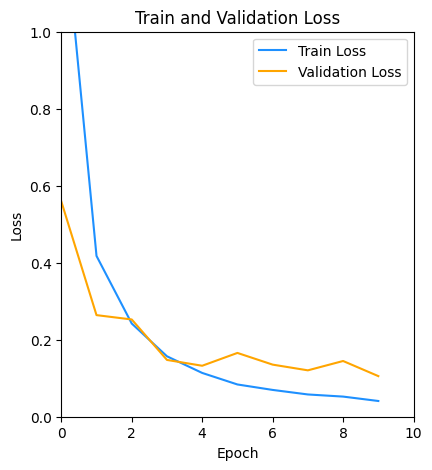

In [ ]:
plt.figure(figsize=(10, 5))

# Plot for Loss
plt.subplot(1, 2, 1)
plt.title("Train and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.plot(history.history['loss'], label="Train Loss", color='dodgerblue')         # blue
plt.plot(history.history['val_loss'], label="Validation Loss", color='orange')    # orange
plt.xlim(0, 10)
plt.ylim(0.0, 1.0)
plt.legend()

## Second Model


In [ ]:
cnn = Sequential()

In [ ]:
cnn.add(Conv2D(filters=32,kernel_size=3,padding='same',activation='relu',input_shape=(256,256,3)))
cnn.add(MaxPooling2D(pool_size=2,strides=2))

In [ ]:
# cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,padding='same',activation='relu'))
# # cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,activation='relu'))
# cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

In [ ]:
cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,padding='same',activation='relu'))
# cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPooling2D(pool_size=2,strides=2))

In [ ]:
cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,padding='same',activation='relu'))
# cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPooling2D(pool_size=2,strides=2))

In [ ]:
# cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,padding='same',activation='relu'))
# cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,activation='relu'))
# cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

In [ ]:
# cnn.add(tf.keras.layers.Dropout(0.25))


In [ ]:
cnn.add(tf.keras.layers.Flatten())


In [ ]:
cnn.add(Dense(units=128,activation='relu'))


In [ ]:
# cnn.add(BatchNormalization())


In [ ]:
# cnn.add(tf.keras.layers.Dense(units=128,activation='relu'))


In [ ]:
# cnn.add(BatchNormalization())


In [ ]:
cnn.add(tf.keras.layers.Dense(units=64,activation='relu'))


In [ ]:
# cnn.add(BatchNormalization())


In [ ]:
# cnn.add(tf.keras.layers.Dropout(0.4)) #To avoid overfitting


In [ ]:
#Output Layer
cnn.add(tf.keras.layers.Dense(units=38,activation='softmax'))

#### Compiling and Training Phase


In [ ]:
cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
cnn.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 128, 128, 128)  │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 64, 64, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 262144)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │    33,554,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 38)             │         2,470 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,898,342 (129.31 MB)

 Trainable params: 33,898,342 (129.31 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model_checkpoint = ModelCheckpoint('plantDiseaseClassification.keras', monitor='val_accuracy', save_best_only=True, mode='max', verbose=1)
early_stopping = EarlyStopping(monitor='val_accuracy', patience=3, verbose=1, mode='max', restore_best_weights=True)

In [ ]:
training_history = cnn.fit(x=training_set,
                           validation_data=validation_set,
                           epochs=10,
                           batch_size=1024,
                           callbacks=[model_checkpoint, early_stopping])


Epoch 1/10
  10/2197 ━━━━━━━━━━━━━━━━━━━━ 3:50 105ms/step - accuracy: 0.9595 - loss: 0.1151

KeyboardInterrupt: 

In [ ]:
plt.figure(figsize=(10, 5))

# Plot for Loss
plt.subplot(1, 2, 1)
plt.title("Train and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.plot(training_history.history['loss'], label="Train Loss", color='dodgerblue')         # blue
plt.plot(training_history.history['val_loss'], label="Validation Loss", color='orange')    # orange
plt.xlim(0, 10)
plt.ylim(0.0, 1.0)
plt.legend()

#### Evaluating Model


In [ ]:
#Training set Accuracy
train_loss, train_acc = cnn.evaluate(training_set)
print('Training accuracy:', train_acc)

1099/1099 ━━━━━━━━━━━━━━━━━━━━ 71s 65ms/step - accuracy: 0.9910 - loss: 0.0307
Training accuracy: 0.9921900629997253


In [ ]:
#Validation set Accuracy
val_loss, val_acc = cnn.evaluate(validation_set)
print('Validation accuracy:', val_acc)

275/275 ━━━━━━━━━━━━━━━━━━━━ 16s 60ms/step - accuracy: 0.8836 - loss: 0.5315
Validation accuracy: 0.8837924003601074


# Saving Best Model


In [ ]:
### Save only one of them
cnn.save('plantDiseaseClassification1.keras')
model.save('plantDiseaseClassification2.keras')


In [ ]:
training_history.history #Return Dictionary of history


In [ ]:
#Recording History in json
import json
with open('training_hist.json','w') as f:
  json.dump(training_history.history,f)

In [ ]:
print(training_history.history.keys())
